In [40]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import seaborn as sns
from tqdm import tqdm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
import warnings


In [41]:
df=pd.read_csv('Ames Housing Dataset (1).csv')
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [43]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [44]:
df.isna().sum()[df.isna().sum()>0]

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

In [45]:
df.drop('Id', axis=1, inplace=True)
df['MSSubClass'] = df['MSSubClass'].astype(str)

### Missing values — نفس الخطوات: mean للأرقام و most_frequent للنصوص

In [46]:

for col in ['LotFrontage', 'MasVnrArea', 'GarageYrBlt']:
    simple_imputer = SimpleImputer(strategy='mean')
    df[[col]]=simple_imputer.fit_transform(df[[col]])

In [47]:
for col in df.select_dtypes(exclude=['number']).columns:
    simple_imputer = SimpleImputer(strategy='most_frequent')
    df[[col]]=simple_imputer.fit_transform(df[[col]])

In [48]:
df.dropna(inplace=True)
df.reset_index(drop=True,inplace=True)

In [49]:
df.duplicated().sum()

np.int64(0)

In [50]:
df.select_dtypes(exclude=['number']).nunique().sort_values()

Alley             2
Street            2
Utilities         2
CentralAir        2
MasVnrType        3
LandSlope         3
PoolQC            3
GarageFinish      3
PavedDrive        3
ExterQual         4
KitchenQual       4
BsmtExposure      4
BsmtQual          4
BsmtCond          4
LandContour       4
LotShape          4
Fence             4
MiscFeature       4
ExterCond         5
HeatingQC         5
Electrical        5
BldgType          5
LotConfig         5
MSZoning          5
FireplaceQu       5
GarageCond        5
GarageQual        5
Foundation        6
BsmtFinType1      6
BsmtFinType2      6
RoofStyle         6
Heating           6
SaleCondition     6
GarageType        6
Functional        7
Condition2        8
HouseStyle        8
RoofMatl          8
Condition1        9
SaleType          9
MSSubClass       15
Exterior1st      15
Exterior2nd      16
Neighborhood     25
dtype: int64

In [51]:
obj_cols = df.select_dtypes(exclude=['number']).columns
binary_cols = [c for c in obj_cols if df[c].nunique() == 2]
multi_cols  = [c for c in obj_cols if df[c].nunique() > 2]
print('Binary :', binary_cols)
print('Multi  :', len(multi_cols), 'columns')

Binary : ['Street', 'Alley', 'Utilities', 'CentralAir']
Multi  : 40 columns


In [52]:
le = LabelEncoder()
for col in binary_cols:
    df[col] = le.fit_transform(df[col])

In [53]:
onehot = OneHotEncoder(
                      sparse_output=False,
                      drop='first',
                      handle_unknown='ignore'
).set_output(transform='pandas')

temp = onehot.fit_transform(df[multi_cols])
df = pd.concat([df,temp],axis=1)
df.drop(multi_cols,axis=1,inplace=True)
print(df.shape)

(1460, 258)


In [54]:
X = df.drop('SalePrice',axis=1)
y = df['SalePrice']

In [55]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [56]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [57]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1),
    "SVM":SVR(kernel='linear', C=100, gamma=1),
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10),
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
}

In [58]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

def store(errors, name, model):
    a = regression_metrics(model, X_train, y_train)
    b = regression_metrics(model, X_test, y_test)
    errors[name] = {"MAE Train":a[0],"MAE Test":b[0],"MSE Train":a[1],"MSE Test":b[1],
                    "RMSE Train":a[2],"RMSE Test":b[2],"R2 Train":a[3],"R2 Test":b[3]}

  0%|          | 0/15 [00:00<?, ?it/s]

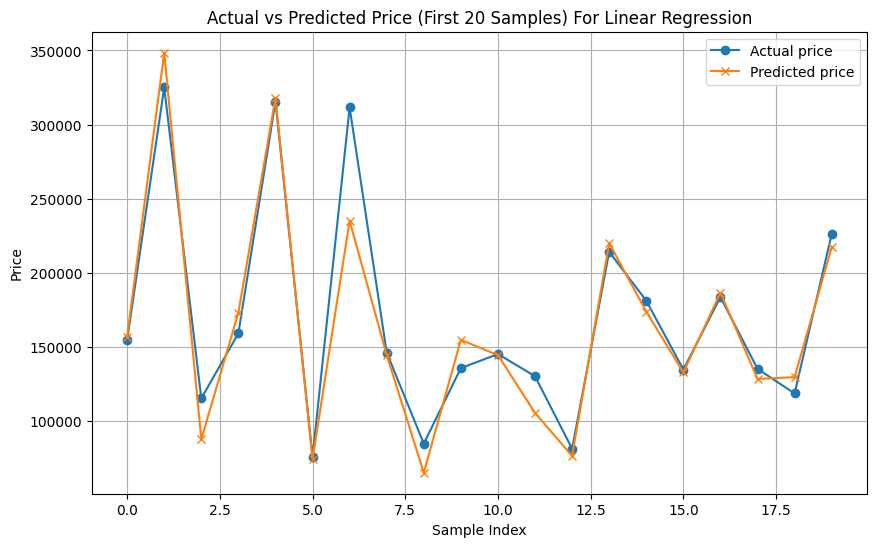

  7%|▋         | 1/15 [00:00<00:07,  2.00it/s]

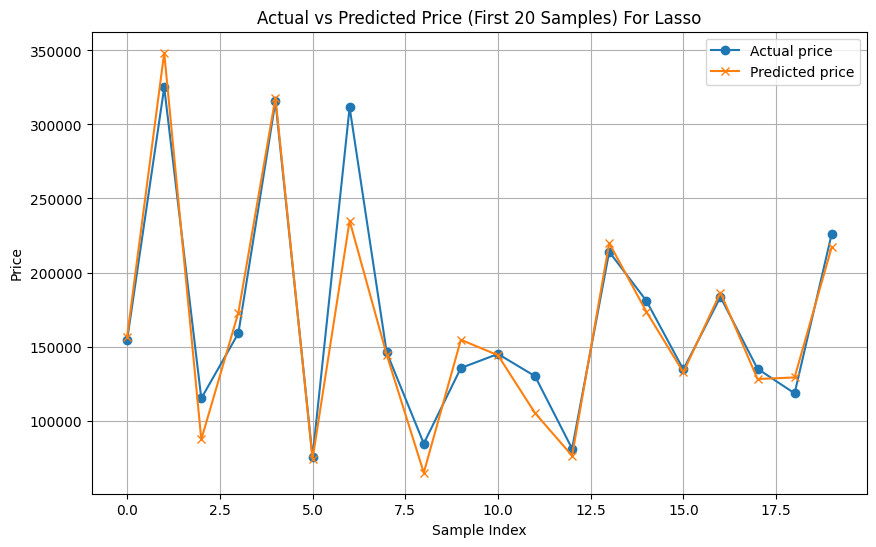

 13%|█▎        | 2/15 [00:01<00:12,  1.02it/s]

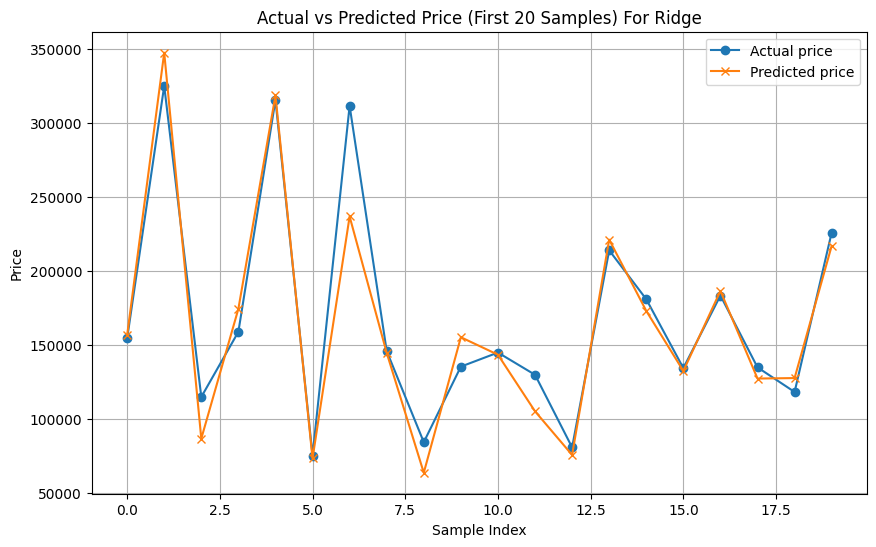

 20%|██        | 3/15 [00:02<00:07,  1.56it/s]

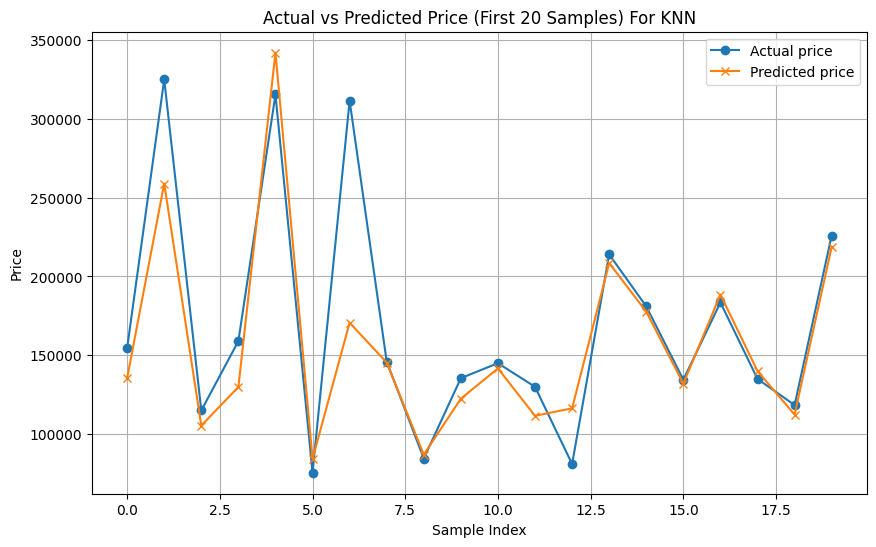

 27%|██▋       | 4/15 [00:02<00:07,  1.45it/s]

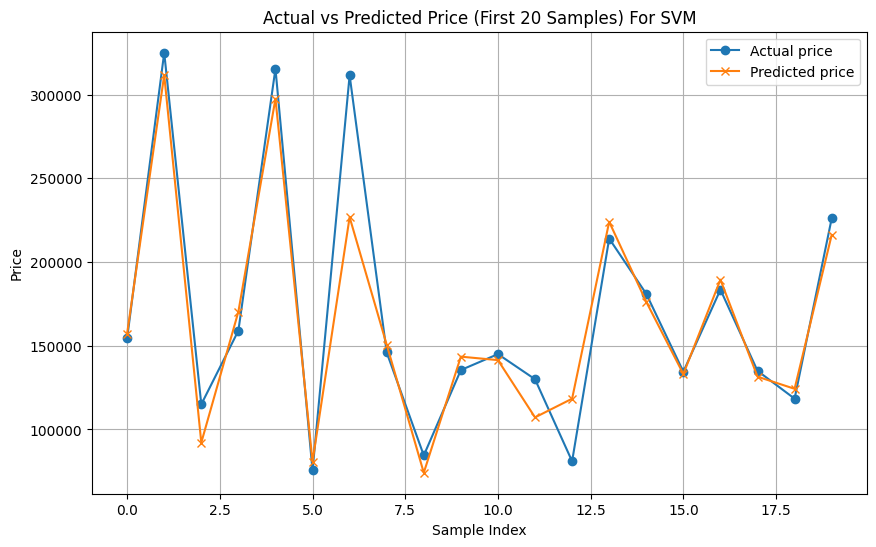

 33%|███▎      | 5/15 [00:03<00:06,  1.50it/s]

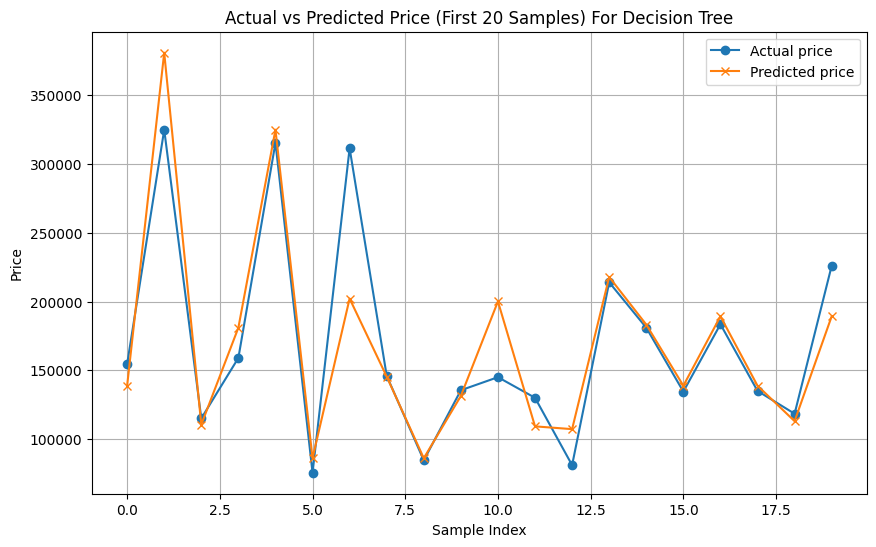

 40%|████      | 6/15 [00:03<00:04,  1.90it/s]

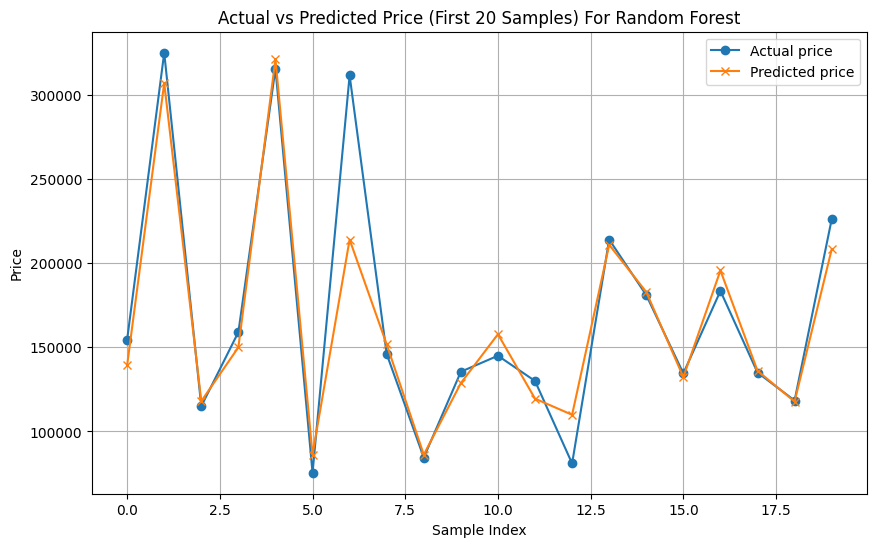

 47%|████▋     | 7/15 [00:05<00:07,  1.04it/s]

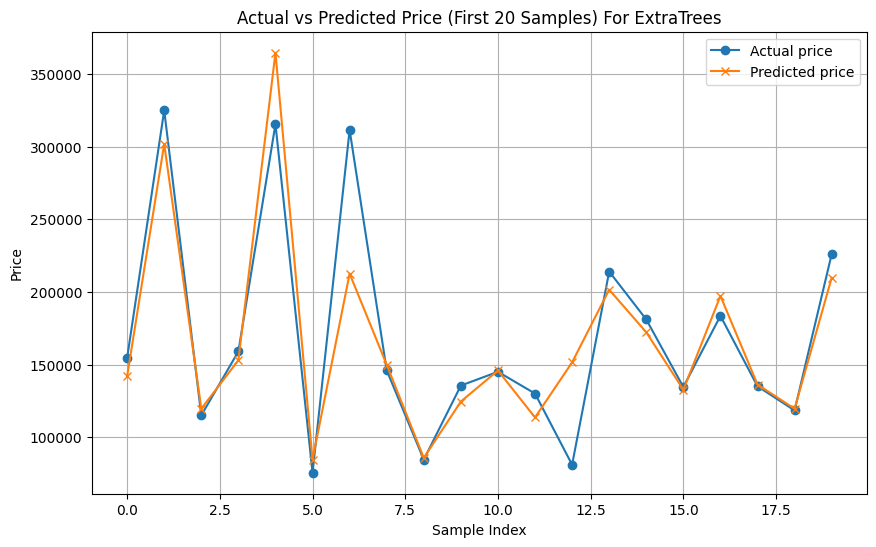

 53%|█████▎    | 8/15 [00:11<00:16,  2.42s/it]

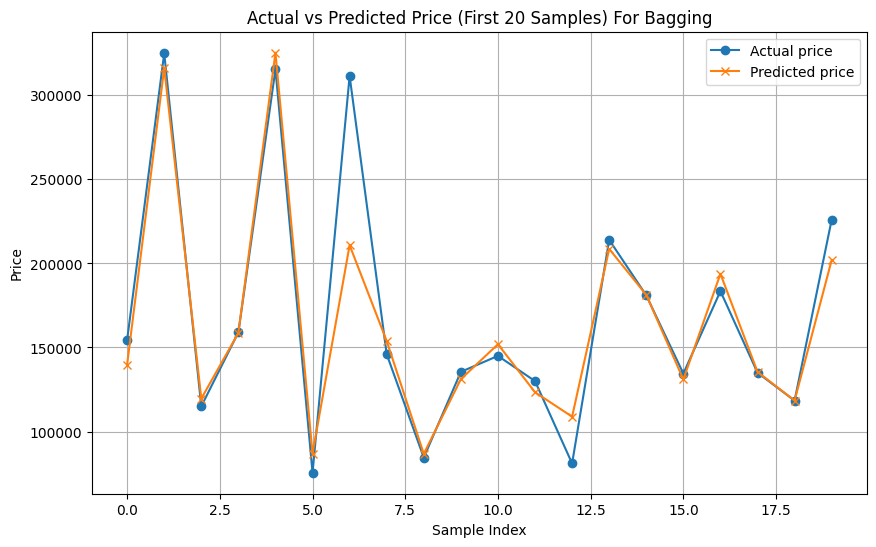

 60%|██████    | 9/15 [00:13<00:14,  2.44s/it]

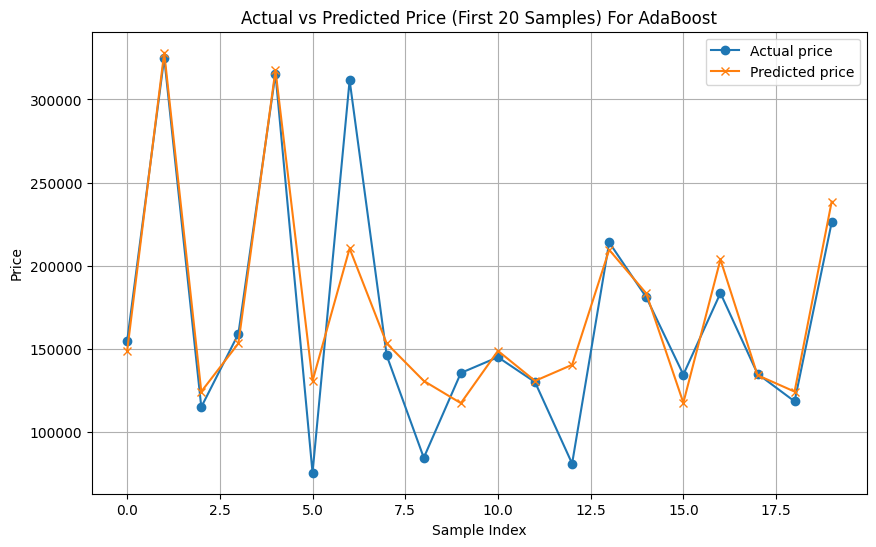

 67%|██████▋   | 10/15 [00:14<00:09,  1.83s/it]

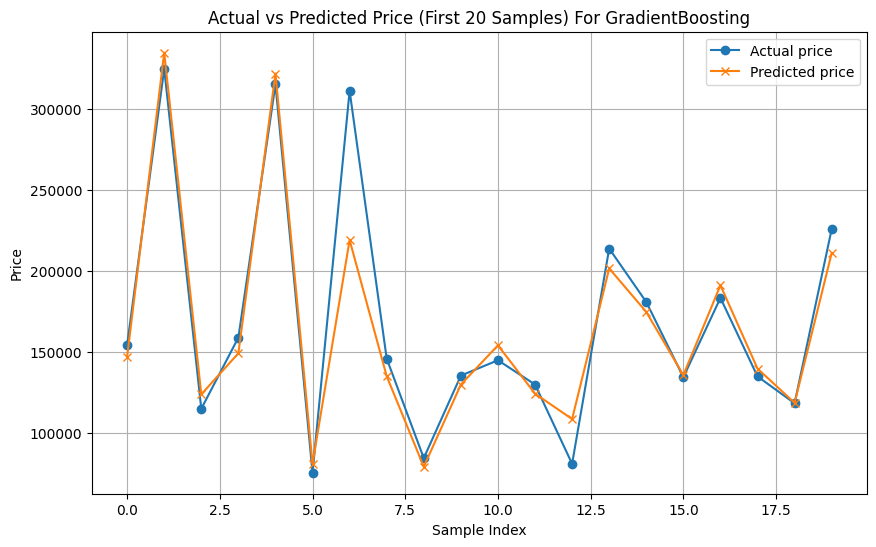

 73%|███████▎  | 11/15 [00:15<00:06,  1.69s/it]

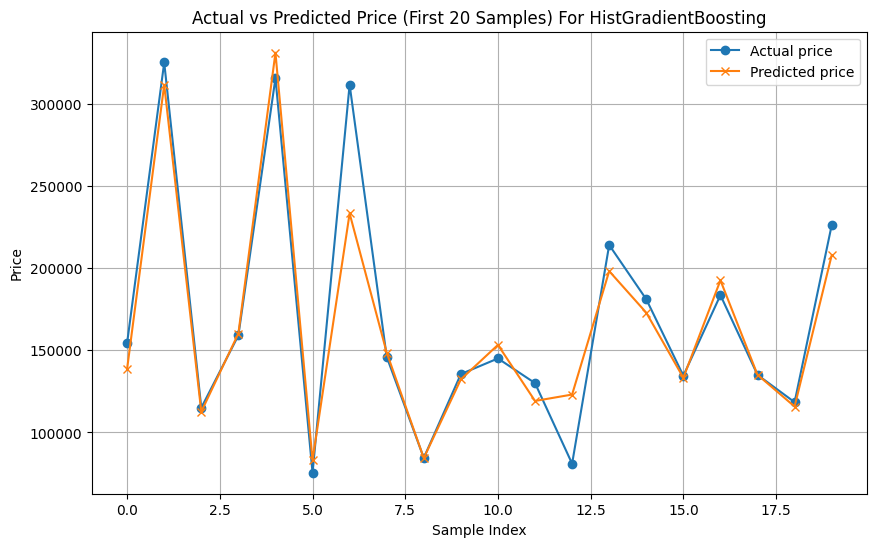

 80%|████████  | 12/15 [00:18<00:06,  2.20s/it]

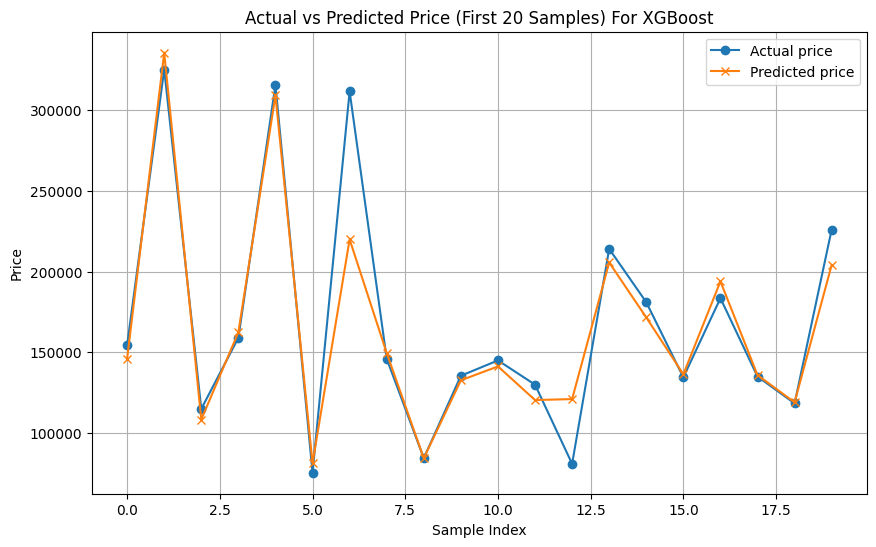

 87%|████████▋ | 13/15 [00:19<00:03,  1.77s/it]

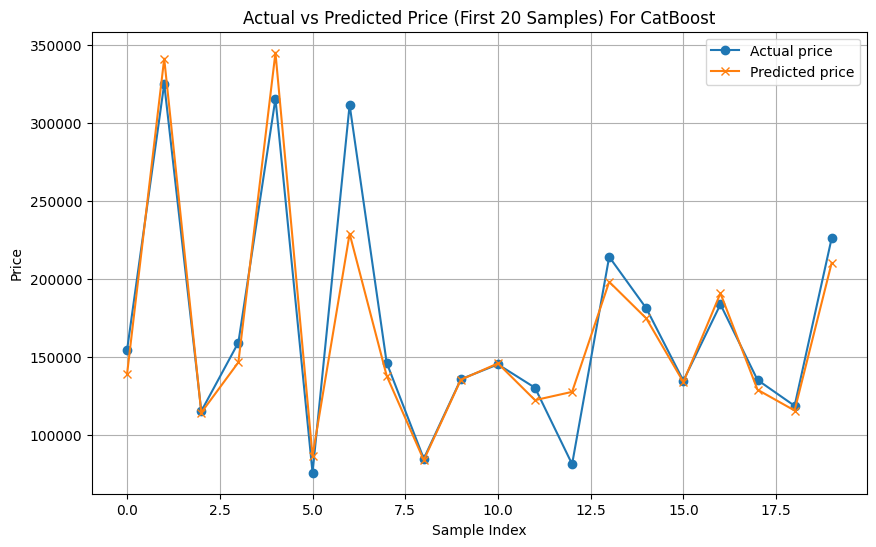

 93%|█████████▎| 14/15 [00:20<00:01,  1.67s/it]

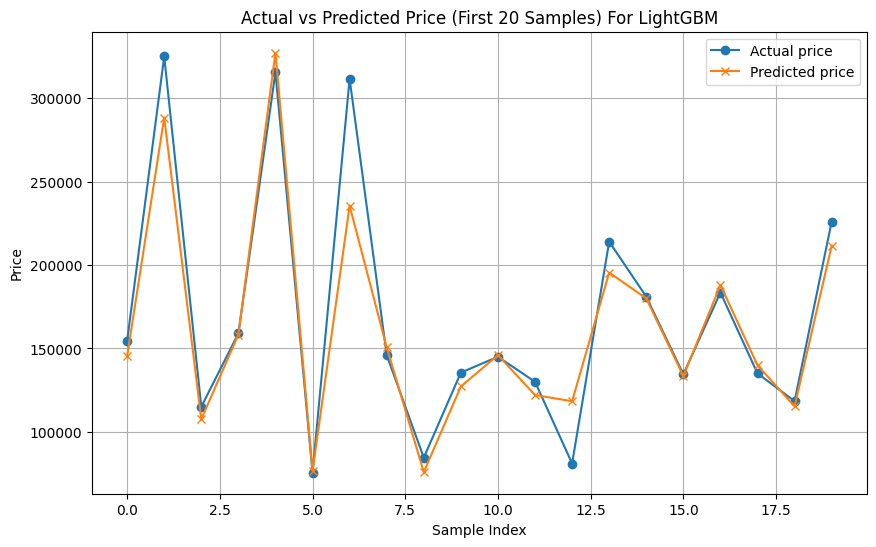

100%|██████████| 15/15 [00:21<00:00,  1.44s/it]


In [59]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    store(errors, model_name, model)

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual price', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted price', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Price')
    plt.title('Actual vs Predicted Price (First 20 Samples) For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [60]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

model1 = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)])
model2 = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)])
# Weighted averaging
model3 = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], weights=[2, 1, 2])

for m in (model1, model2, model3):
    m.fit(X_train, y_train)

store(errors, "Voting", model1)
store(errors, "Simple Voting", model2)
store(errors, "Weighted Voting", model3)

In [61]:
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42, verbose=-1))
]
meta_regressor = XGBRegressor()

stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)
stacking_regressor.fit(X_train, y_train)
store(errors, "Stacking", stacking_regressor)

In [62]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
XGBoost,3816.589844,16794.021484,2.650782e+07,6.956157e+08,5148.574366,26374.528318,0.995556,0.909311
CatBoost,11753.514034,17225.221061,2.664506e+08,7.676579e+08,16323.314780,27706.640261,0.955328,0.899918
GradientBoosting,9991.271601,17538.776163,1.871119e+08,7.721861e+08,13678.886649,27788.236714,0.968629,0.899328
Stacking,5765.320312,16886.736328,8.510942e+07,8.287310e+08,9225.476898,28787.688480,0.985731,0.891956
Random Forest,8084.869574,18120.688134,1.583752e+08,8.434636e+08,12584.720319,29042.445478,0.973447,0.890035
ExtraTrees,0.000000,17816.684760,0.000000e+00,8.530983e+08,0.000000,29207.845933,1.000000,0.888779
LightGBM,5417.396146,16810.761958,1.319572e+08,8.552483e+08,11487.262103,29244.627721,0.977876,0.888499
HistGradientBoosting,5431.894342,17009.963703,1.319286e+08,8.700590e+08,11486.016514,29496.761729,0.977881,0.886568
Bagging,8215.648902,18280.510674,1.632612e+08,9.038875e+08,12777.371281,30064.721758,0.972628,0.882158
SVM,13612.911206,17929.603736,8.671462e+08,1.071264e+09,29447.346902,32730.172213,0.854617,0.860337


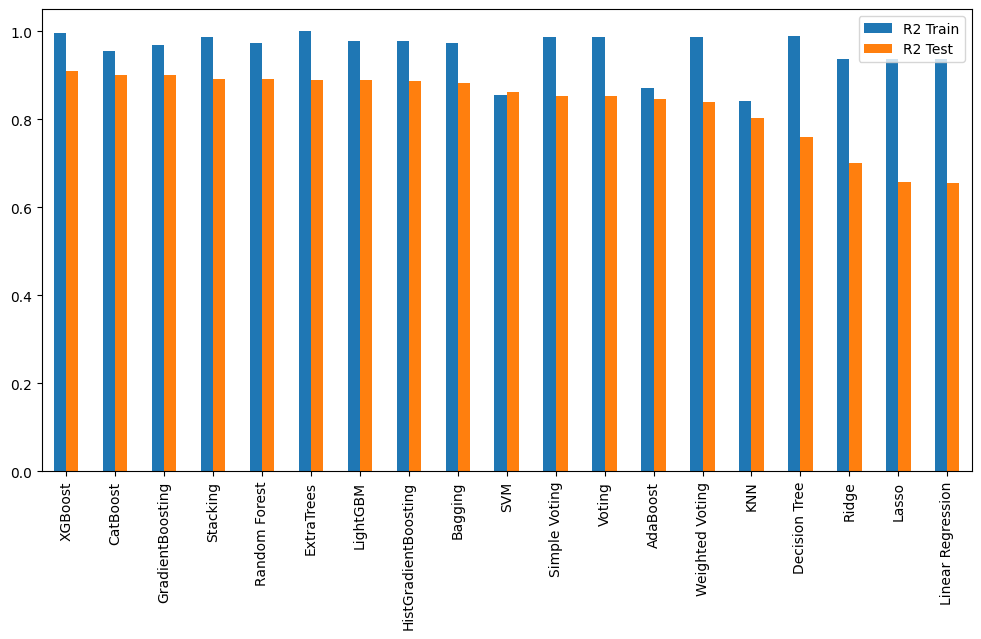

In [63]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))
plt.show()

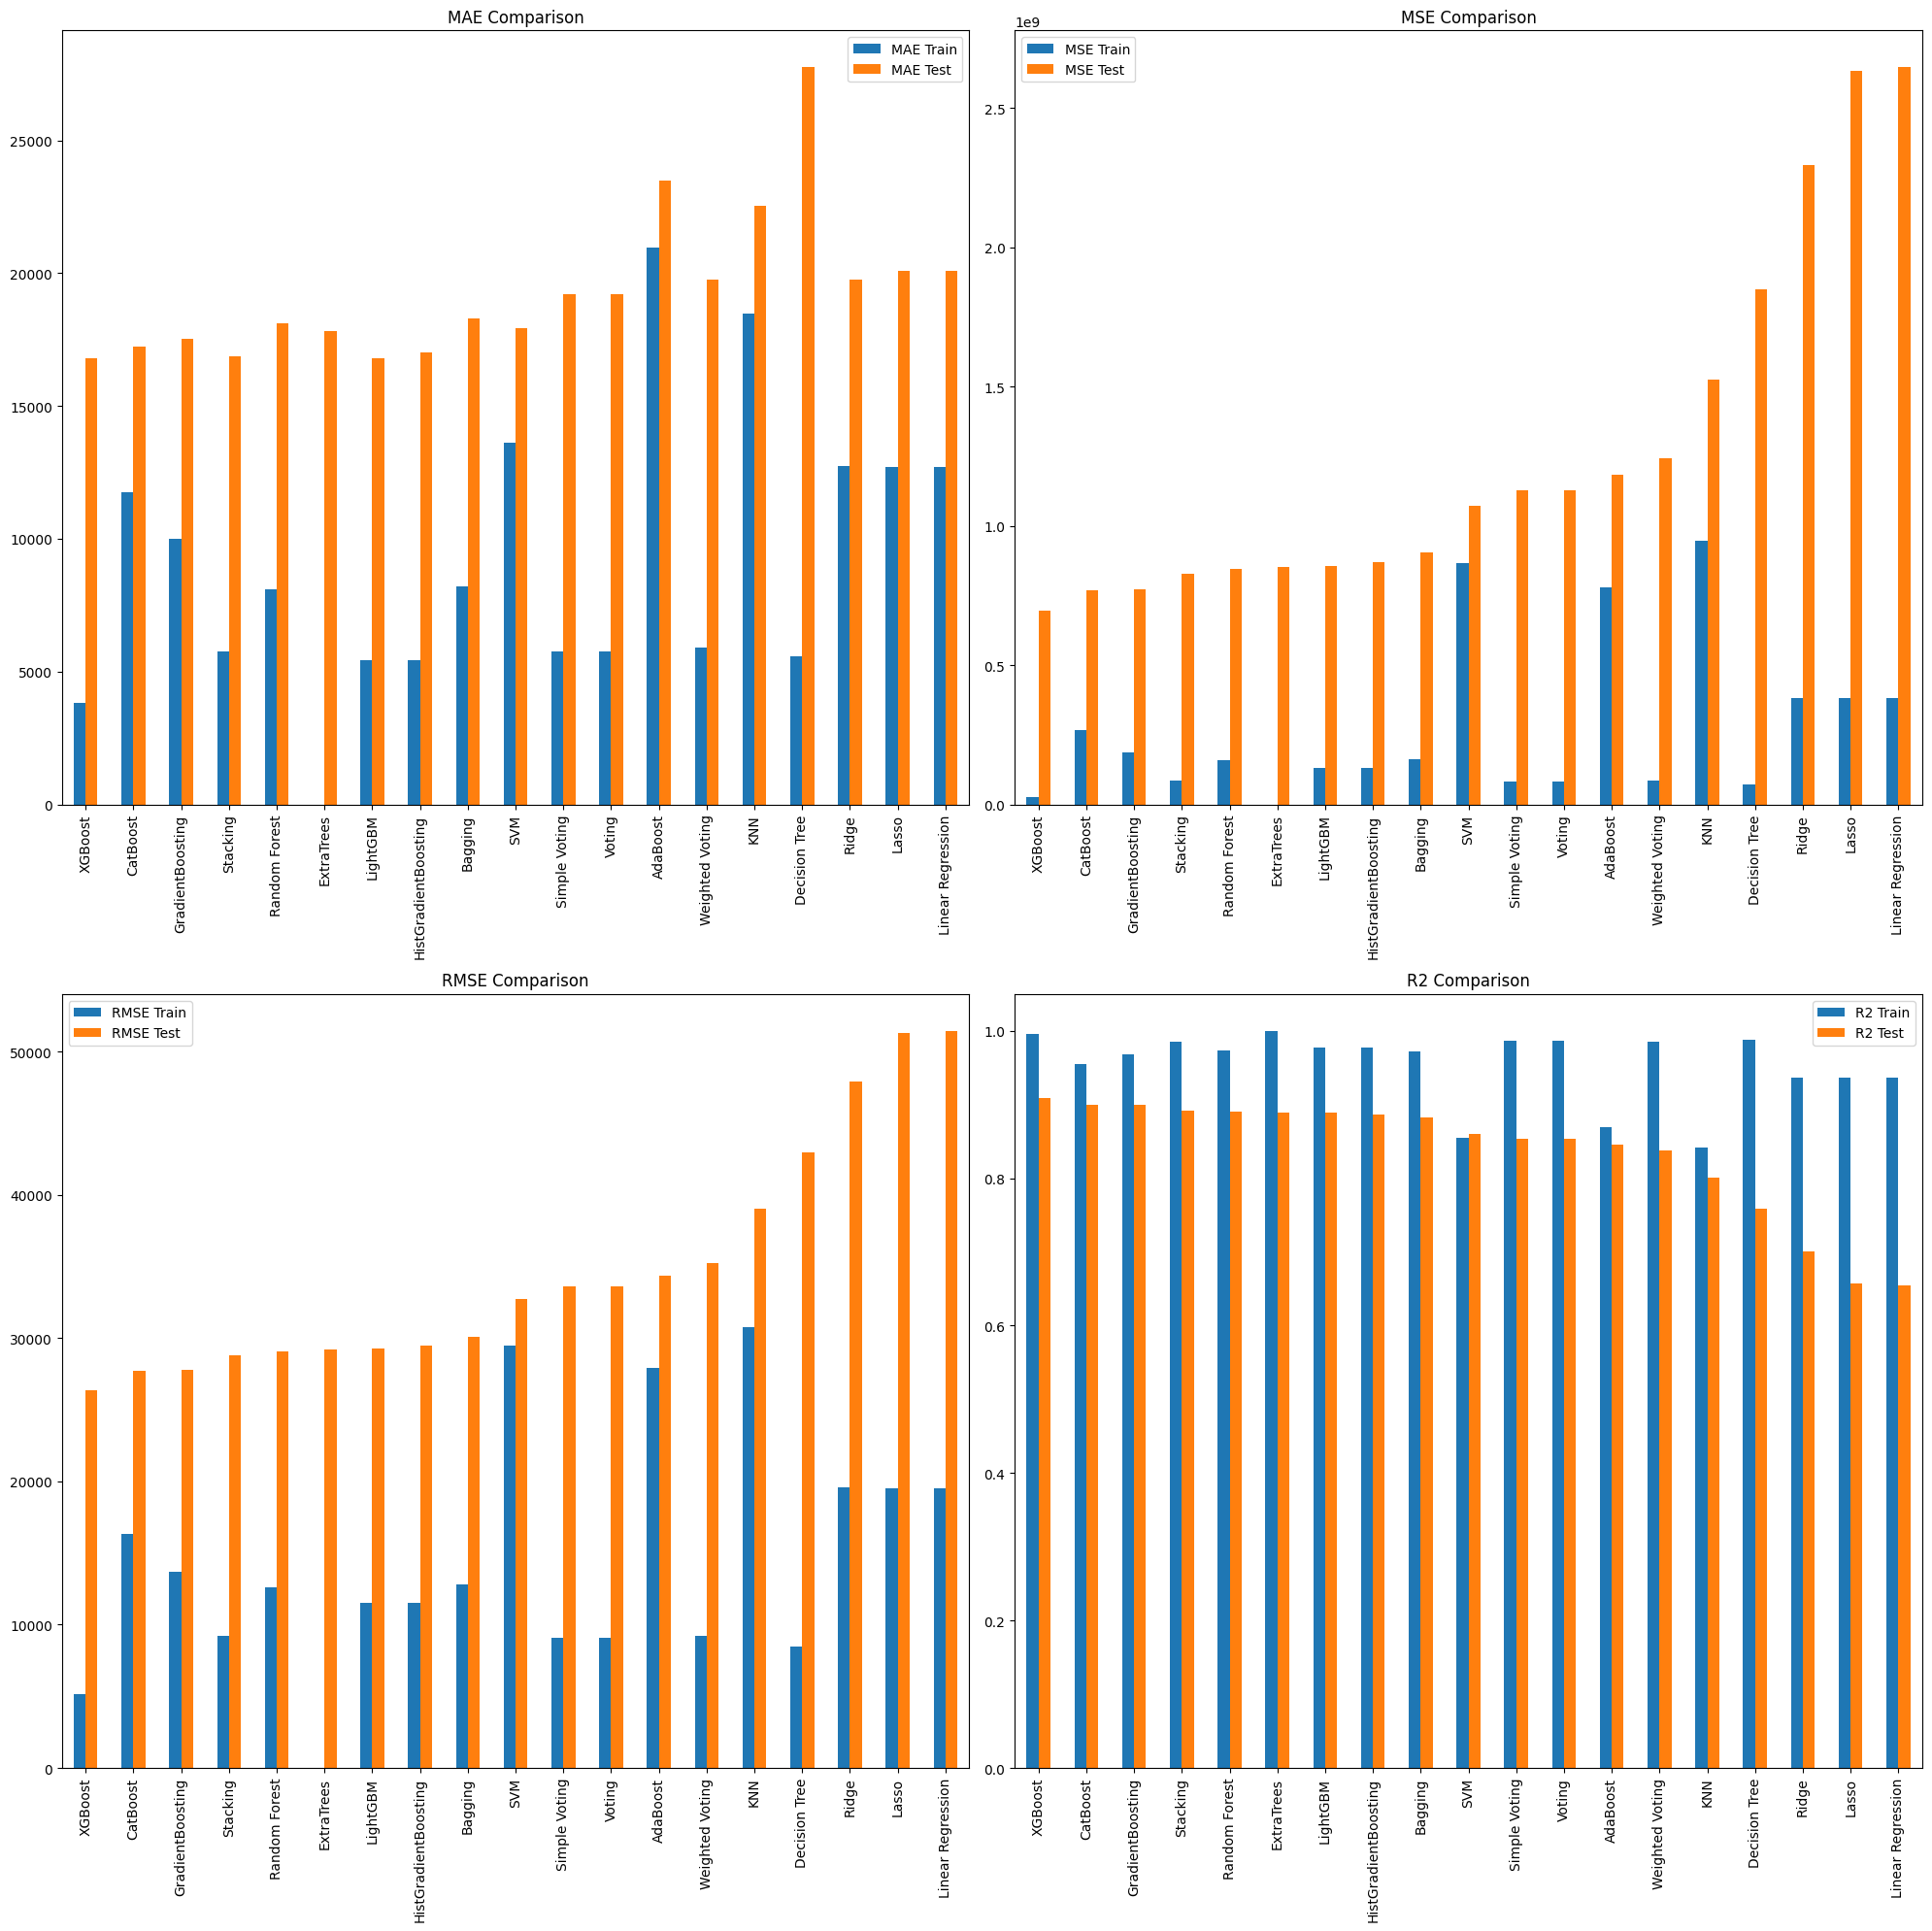

In [64]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))
for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')
plt.tight_layout()
plt.show()